# Análise Exploratória de Dados (EDA) em SQL — SOP/PCOS

Dados do dataset *Polycystic ovary syndrome (PCOS)* (Kaggle), transformados em um banco relacional no SQLite segundo o esquema do relatório parcial.

## 0. Imports e funções auxiliares

In [1]:
import numpy as np
import pandas as pd
import sqlite3

import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

pd.set_option('display.max_columns', None)

# pasta onde os gráficos são salvos
from pathlib import Path
PASTA_UNIVARIADA = Path('graficos/univariada')
PASTA_MULTIVARIADA = Path('graficos/multivariada')
for pasta in (PASTA_UNIVARIADA, PASTA_MULTIVARIADA):
    pasta.mkdir(parents=True, exist_ok=True)

In [2]:
def fetch(query, conn, formatted=True):
    # executa a consulta e busca todas as linhas
    cur = conn.cursor()
    cur.execute(query)
    rs = cur.fetchall()

    # extrai os nomes das colunas da descrição do cursor
    columns = [desc[0] for desc in cur.description]

    # retorna um dataframe com os nomes das colunas
    return pd.DataFrame(rs, columns=columns) if formatted else rs

def show_tables(conn):
    return [x[0] for x in fetch("SELECT tbl_name FROM sqlite_master WHERE type = 'table'", conn, False)]

def shape(table, conn):
    nrows = fetch(f'SELECT COUNT(*) FROM "{table}"', conn, False)[0][0]
    ncols = fetch(f"SELECT COUNT(*) FROM pragma_table_info('{table}')", conn, False)[0][0]

    return (nrows, ncols)

def desc(table, conn):
    cur = conn.cursor()
    cur.execute(f'PRAGMA table_info("{table}")')
    columns = [row[1] for row in cur.fetchall()]

    return columns

def info(table, conn):
    # restrições da tabela (domínio, nulo, default, pk)
    df1 = fetch(f'PRAGMA table_info("{table}")', conn)
    columns = desc(table, conn)

    # entradas por coluna
    counts = ', '.join([f'COUNT(*) AS "{column}"' for column in columns])
    df2 = fetch(f'SELECT {counts} FROM "{table}"', conn).transpose()
    df2.columns = ['count']

    # entradas não nulas por coluna
    counts = ', '.join([f'COUNT("{column}") AS "{column}"' for column in columns])
    df3 = fetch(f'SELECT {counts} FROM "{table}"', conn).transpose()
    df3.columns = ['notnull count']

    # entradas não nulas distintas por coluna
    counts = ', '.join([f'COUNT(DISTINCT "{column}") AS "{column}"' for column in columns])
    df4 = fetch(f'SELECT {counts} FROM "{table}"', conn).transpose()
    df4.columns = ['unique count']

    return df1.merge(df2, left_on='name', right_index=True) \
            .merge(df3, left_on='name', right_index=True) \
            .merge(df4, left_on='name', right_index=True)

In [3]:
# cores fixas do diagnóstico: azul = sem SOP, vermelho = com SOP
ROTULOS_SOP = {0: 'Sem SOP', 1: 'Com SOP'}
CORES_SOP = {'Sem SOP': '#1f77b4', 'Com SOP': '#d62728'}
COR_NEUTRA = '#7f7f7f'

def histograma(df, coluna, rotulo=None, diferenciar=True, r=None, bins='auto', ax=None, arquivo=None):
    """Histograma (seaborn) de `coluna`.
    diferenciar=True  -> barras empilhadas por diagnóstico (azul = sem SOP, vermelho = com SOP)
    diferenciar=False -> histograma simples, numa cor neutra
    r                 -> correlação com o diagnóstico, exibida na legenda
    arquivo           -> caminho do PNG a salvar (opcional)"""
    dados = pd.DataFrame({coluna: df[coluna], 'Diagnóstico': df['pcos'].map(ROTULOS_SOP)})
    dados = dados.dropna(subset=[coluna])
    nulos = df[coluna].isna().sum()

    # variável categórica (texto) ou numérica com poucos valores -> uma barra por valor
    numerica = pd.api.types.is_numeric_dtype(dados[coluna])
    valores = set(dados[coluna].unique())
    discreta = (not numerica) or (len(valores) <= 15 and all(float(v).is_integer() for v in valores))
    estilo = dict(discrete=True, shrink=0.8) if discreta else dict(bins=bins)

    if ax is None:
        _, ax = plt.subplots(figsize=(8, 4))
    if diferenciar:
        sns.histplot(data=dados, x=coluna, hue='Diagnóstico', hue_order=list(CORES_SOP),
                     palette=CORES_SOP, multiple='stack', ax=ax, **estilo)
        if r is not None:
            ax.get_legend().set_title(f'Diagnóstico\nr com SOP = {r:+.3f}')
    else:
        sns.histplot(data=dados, x=coluna, color=COR_NEUTRA, label='Todas as pacientes', ax=ax, **estilo)
        texto_r = f'{r:+.3f}' if r is not None else 'não se aplica'
        ax.legend(title=f'r com SOP = {texto_r}')

    if numerica and valores <= {0, 1}:          # variáveis sim/não
        ax.set_xticks([0, 1], ['Não', 'Sim'])
    ax.set_title(f'{rotulo or coluna}  (n = {len(dados)}, nulos = {nulos})')
    ax.set_xlabel(rotulo or coluna)
    ax.set_ylabel('Frequência')
    plt.tight_layout()
    if arquivo:
        ax.figure.savefig(arquivo, dpi=150, bbox_inches='tight')
    plt.show()

def matriz_correlacao(df, colunas=None, rotulos=None, metodo='pearson', titulo=None, arquivo=None):
    """Matriz de correlação (plotly) das colunas numéricas; mostra só o triângulo inferior."""
    num = df[colunas or list(df.columns)].select_dtypes('number')
    corr = num.corr(method=metodo)
    if rotulos:
        corr = corr.rename(index=rotulos, columns=rotulos)
    corr = corr.where(np.tril(np.ones(corr.shape, dtype=bool)))

    n = len(corr)
    fig = px.imshow(corr, text_auto='.2f', zmin=-1, zmax=1, aspect='auto',
                    color_continuous_scale='RdBu_r',
                    title=titulo or f'Matriz de correlação ({metodo})')
    fig.update_traces(textfont_size=8 if n > 20 else 11)
    fig.update_layout(width=max(600, 28 * n + 250), height=max(500, 28 * n + 150),
                      xaxis_tickangle=-60, plot_bgcolor='white')
    if arquivo:                                # PNG estático (requer o pacote kaleido)
        fig.write_image(arquivo, scale=2)
    fig.show()
    return fig

def vetor_correlacao(df, linhas, colunas=None, rotulos=None, metodo='pearson', ordenar=False, titulo=None,
                     arquivo=None):
    """Vetor(es) de correlação (plotly): cada variável de `linhas` contra cada uma de `colunas`.
    Sem `colunas`, usa todas as demais colunas numéricas. Com mais de 12 colunas, o vetor fica na vertical.
    ordenar=True ordena as colunas pelo maior |r|."""
    num = df.select_dtypes('number')
    colunas = colunas or [c for c in num.columns if c not in linhas]
    corr = num[list(dict.fromkeys(linhas + colunas))].corr(method=metodo).loc[linhas, colunas]
    if ordenar:
        corr = corr[corr.abs().max().sort_values(ascending=False).index]
    if rotulos:
        corr = corr.rename(index=rotulos, columns=rotulos)

    vertical = corr.shape[1] > 12
    if vertical:
        corr = corr.T
    fig = px.imshow(corr, text_auto='.2f', zmin=-1, zmax=1, aspect='auto',
                    color_continuous_scale='RdBu_r',
                    title=titulo or f'Vetor de correlação ({metodo})')
    nl, nc = corr.shape
    fig.update_layout(width=max(750 if vertical else 500, 130 * nc + 300), height=max(300, (28 if vertical else 60) * nl + 180),
                      plot_bgcolor='white')
    if arquivo:                                # PNG estático (requer o pacote kaleido)
        fig.write_image(arquivo, scale=2)
    fig.show()
    return corr

## 1. Ingestão dos dados

Fonte: https://www.kaggle.com/datasets/prasoonkottarathil/polycystic-ovary-syndrome-pcos (arquivo `PCOS_data_without_infertility.xlsx`, aba `Full_new`). A planilha é carregada como está, com todos os valores em texto, numa tabela `Source` do SQLite. A limpeza e a normalização são feitas depois, em SQL.

In [4]:
source = 'data/PCOS_data_without_infertility.xlsx'

# conecta ao banco SQLite (o arquivo é criado se não existir)
conn = sqlite3.connect('pcos.db')
cur = conn.cursor()

# começa do zero a cada execução: remove visões e tabelas de execuções anteriores
cur.execute('PRAGMA foreign_keys = OFF')
for tipo, nome in cur.execute("SELECT type, name FROM sqlite_master WHERE type IN ('view', 'table')").fetchall():
    cur.execute(f'DROP {tipo.upper()} IF EXISTS "{nome}"')

# lê a planilha (tudo como texto) e remove espaços nas bordas dos nomes das colunas
planilha = pd.read_excel(source, sheet_name='Full_new', dtype=str)
planilha.columns = [c.strip() for c in planilha.columns]
planilha = planilha.drop(columns=[c for c in planilha.columns if c.startswith('Unnamed')])
header = list(planilha.columns)

# cria a tabela Source com as colunas da planilha
columns = [f'"{column}"' for column in header]
cur.execute(f'CREATE TABLE Source ({", ".join(columns)})')

# insere todas as linhas
placeholders = ', '.join(['?'] * len(header))
cur.executemany(f'INSERT INTO Source VALUES ({placeholders})', planilha.fillna('').values.tolist())

# anula valores vazios, para que sejam reconhecidos como nulos de verdade
for column in columns:
    cur.execute(f"UPDATE Source SET {column} = NULLIF(TRIM({column}), '')")

conn.commit()

## 2. Entendimento dos dados

In [5]:
# tabelas do banco
show_tables(conn)

['Source']

In [6]:
# formato da tabela -- análogo ao shape do pandas
shape('Source', conn)

(541, 44)

In [7]:
# info da tabela -- análogo ao .info() / .nunique() do pandas
info('Source', conn)

,cid,name,type,notnull,dflt_value,pk,count,notnull count,unique count
0,0,Sl. No,,0,None,0,541,541,541
1,1,Patient File No.,,0,None,0,541,541,541
2,2,PCOS (Y/N),,0,None,0,541,541,2
3,3,Age (yrs),,0,None,0,541,541,29
4,4,Weight (Kg),,0,None,0,541,541,117
5,5,Height(Cm),,0,None,0,541,541,50
6,6,BMI,,0,None,0,541,541,355
7,7,Blood Group,,0,None,0,541,541,8
8,8,Pulse rate(bpm),,0,None,0,541,541,11
9,9,RR (breaths/min),,0,None,0,541,541,8


In [8]:
# linhas aleatórias -- análogo ao sample() do pandas
fetch('SELECT * FROM Source ORDER BY random() LIMIT 5', conn)

,Sl. No,Patient File No.,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),Hb(g/dl),Cycle(R/I),Cycle length(days),Marraige Status (Yrs),Pregnant(Y/N),No. of aborptions,I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),FSH(mIU/mL),LH(mIU/mL),FSH/LH,Hip(inch),Waist(inch),Waist:Hip Ratio,TSH (mIU/L),AMH(ng/mL),PRL(ng/mL),Vit D3 (ng/mL),PRG(ng/mL),RBS(mg/dl),Weight gain(Y/N),hair growth(Y/N),Skin darkening (Y/N),Hair loss(Y/N),Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm)
0,330,330,0,29,53,161,20.4,15,72,18,10.2,2,6,5,1,0,900.6,900.6,5052,3.68,1372.826087,38,35,0.9210526316,0.83,3.5,30.58,28.6,0.3,108,0,0,0,1,1,1,0,110,80,6,4,16,17,6
1,240,240,0,20,56,159,22.15102251,13,72,18,12.4,2,5,1.5,1,0,389.26,41.77,5.9,3.13,1.884984026,35,33,0.9428571429,0.61,7.3,10.6,22,0.25,86,0,0,0,0,1,0,1,120,80,10,5,15,18,8
2,518,518,0,27,59,152,25.2,11,72,18,11.5,2,5,2,0,0,320.07,1.99,5.95,3.9,1.525641026,36,34,0.9444444444,2.21,5.4,35.19,24.2,0.5,92,0,0,0,0,0,0,0,110,70,5,8,20,21,9.8
3,534,534,1,26,53.5,161.544,20.5,14,70,18,10.6,4,7,3,0,0,572.86,5.81,3.71,4.66,0.7961373391,28,26,0.9285714286,1.4,19.6,29.57,32.1,0.36,100,0,0,0,0,1,0,0,110,80,8,10,18,18,10.3
4,336,336,0,30,46,161,17.7,15,78,22,10.8,2,5,5,1,0,8012.99,4176,2.44,0.22,11.09090909,34,31,0.9117647059,0.79,3.3,14.98,13.4,0.89,100,0,0,0,1,1,0,0,110,80,2,2,14,15,9


## 3. Limpeza dos dados

Todas as colunas da planilha deveriam ser numéricas. A consulta abaixo procura valores com algum caractere que não seja dígito ou ponto, ou com mais de um ponto.

In [9]:
def nao_numericos(conn):
    partes = [f'''SELECT "Patient File No." AS paciente, '{c}' AS coluna, "{c}" AS valor
                  FROM Source WHERE "{c}" GLOB '*[^0-9.]*' OR "{c}" GLOB '*.*.*' ''' for c in header]
    return fetch(' UNION ALL '.join(partes), conn)

nao_numericos(conn)

,paciente,coluna,valor
0,124,II beta-HCG(mIU/mL),1.99.
1,306,AMH(ng/mL),a


In [10]:
# '1.99.' é erro de digitação -> 1.99
cur.execute('''UPDATE Source SET "II    beta-HCG(mIU/mL)" = '1.99'
               WHERE "II    beta-HCG(mIU/mL)" = '1.99.' ''')

# 'a' não é um valor de AMH -> nulo (o exame é descartado para essa paciente)
cur.execute('''UPDATE Source SET "AMH(ng/mL)" = NULL WHERE "AMH(ng/mL)" = 'a' ''')

conn.commit()
nao_numericos(conn)

,paciente,coluna,valor


In [11]:
# ciclo menstrual: 2 = regular, 4 = irregular; o código 5 não existe na codificação da planilha
# (será gravado como nulo na migração)
fetch('SELECT "Cycle(R/I)" AS codigo, COUNT(*) AS pacientes FROM Source GROUP BY 1 ORDER BY 1', conn)

,codigo,pacientes
0,2,390
1,4,150
2,5,1


## 4. Normalização

### Observações principais

1. O dataset é centrado na paciente, identificada pelo nº do prontuário (`Patient File No.`) -> chave primária de `Paciente`.
2. Nenhum atributo tem tipo definido (tudo é texto) -> definir domínios e restrições.
3. O tipo sanguíneo é um código (11 a 18) que representa grupo ABO e fator Rh -> tabela própria `TipoSanguineo`, referenciada por chave estrangeira.
4. Grupos de colunas com o mesmo significado (11 exames, 5 sintomas, 2 hábitos) -> entidades `TipoExame`, `Sintoma` e `Habito`, com as tabelas associativas `Realiza` (com o valor do exame), `Apresenta` e `Pratica`.
5. As colunas dos ovários esquerdo e direito descrevem a mesma coisa -> entidade fraca `AvaliacaoOvariana`, identificada por (paciente, lado).
6. IMC e razão cintura/quadril podem ser calculados a partir de outras colunas -> não são armazenados; ficam na visão `vw_paciente_indices`.

### Migração dos dados

#### Esquema de destino

In [12]:
# define domínios, not null, chaves primárias e estrangeiras
cur.executescript('''
CREATE TABLE TipoSanguineo(
  codigo     INTEGER PRIMARY KEY,
  grupo_abo  TEXT NOT NULL CHECK (grupo_abo IN ('A','B','AB','O')),
  fator_rh   TEXT NOT NULL CHECK (fator_rh IN ('+','-')));

CREATE TABLE Paciente(
  id_paciente       INTEGER PRIMARY KEY,
  codigo_sangue     INTEGER NOT NULL REFERENCES TipoSanguineo(codigo),
  pcos              INTEGER NOT NULL CHECK (pcos IN (0,1)),
  idade             INTEGER,
  peso_kg           REAL,
  altura_cm         REAL,
  cintura_pol       REAL,
  quadril_pol       REAL,
  pulso_bpm         INTEGER,
  freq_respiratoria INTEGER,
  pa_sistolica      INTEGER,
  pa_diastolica     INTEGER,
  tipo_ciclo        TEXT CHECK (tipo_ciclo IN ('R','I')),
  duracao_ciclo     INTEGER,
  gestante          INTEGER CHECK (gestante IN (0,1)),
  n_abortos         INTEGER,
  anos_casamento    REAL,
  endometrio_mm     REAL);

CREATE TABLE TipoExame(
  id_exame   INTEGER PRIMARY KEY,
  nome       TEXT NOT NULL,
  unidade    TEXT NOT NULL,
  categoria  TEXT NOT NULL);

CREATE TABLE Sintoma(
  id_sintoma INTEGER PRIMARY KEY,
  nome       TEXT NOT NULL,
  descricao  TEXT NOT NULL);

CREATE TABLE Habito(
  id_habito  INTEGER PRIMARY KEY,
  nome       TEXT NOT NULL,
  descricao  TEXT NOT NULL);

CREATE TABLE AvaliacaoOvariana(
  id_paciente          INTEGER NOT NULL,
  lado                 TEXT NOT NULL CHECK (lado IN ('E','D')),
  quantidade_foliculos INTEGER,
  tamanho_medio_mm     REAL,
  PRIMARY KEY (id_paciente, lado),
  FOREIGN KEY (id_paciente) REFERENCES Paciente(id_paciente) ON DELETE CASCADE);

CREATE TABLE Realiza(
  id_paciente INTEGER NOT NULL,
  id_exame    INTEGER NOT NULL,
  valor       REAL NOT NULL,
  PRIMARY KEY (id_paciente, id_exame),
  FOREIGN KEY (id_paciente) REFERENCES Paciente(id_paciente) ON DELETE CASCADE,
  FOREIGN KEY (id_exame)    REFERENCES TipoExame(id_exame));

CREATE TABLE Apresenta(
  id_paciente INTEGER NOT NULL,
  id_sintoma  INTEGER NOT NULL,
  PRIMARY KEY (id_paciente, id_sintoma),
  FOREIGN KEY (id_paciente) REFERENCES Paciente(id_paciente) ON DELETE CASCADE,
  FOREIGN KEY (id_sintoma)  REFERENCES Sintoma(id_sintoma));

CREATE TABLE Pratica(
  id_paciente INTEGER NOT NULL,
  id_habito   INTEGER NOT NULL,
  PRIMARY KEY (id_paciente, id_habito),
  FOREIGN KEY (id_paciente) REFERENCES Paciente(id_paciente) ON DELETE CASCADE,
  FOREIGN KEY (id_habito)   REFERENCES Habito(id_habito));

-- atributos derivados: calculados, não armazenados
CREATE VIEW vw_paciente_indices AS
SELECT id_paciente, pcos, idade,
       ROUND(peso_kg / ((altura_cm/100.0) * (altura_cm/100.0)), 2) AS imc,
       ROUND(cintura_pol / quadril_pol, 2) AS razao_cintura_quadril
FROM Paciente;
''')
cur.execute('PRAGMA foreign_keys = ON')
show_tables(conn)

['Source',
 'TipoSanguineo',
 'Paciente',
 'TipoExame',
 'Sintoma',
 'Habito',
 'AvaliacaoOvariana',
 'Realiza',
 'Apresenta',
 'Pratica']

#### Tabelas de referência

Os códigos de tipo sanguíneo seguem a aba `Instructions` da planilha. Cada exame, sintoma e hábito guarda também o nome da coluna de origem na `Source`, usado nas migrações seguintes.

In [13]:
tipos_sangue = [(11,'A','+'),(12,'A','-'),(13,'B','+'),(14,'B','-'),
                (15,'O','+'),(16,'O','-'),(17,'AB','+'),(18,'AB','-')]
exames = [
    (1,'Beta-HCG I','mIU/mL','Hormonal','I   beta-HCG(mIU/mL)'),
    (2,'Beta-HCG II','mIU/mL','Hormonal','II    beta-HCG(mIU/mL)'),
    (3,'FSH','mIU/mL','Hormonal','FSH(mIU/mL)'),
    (4,'LH','mIU/mL','Hormonal','LH(mIU/mL)'),
    (5,'TSH','mIU/L','Hormonal','TSH (mIU/L)'),
    (6,'AMH','ng/mL','Hormonal','AMH(ng/mL)'),
    (7,'Prolactina','ng/mL','Hormonal','PRL(ng/mL)'),
    (8,'Vitamina D3','ng/mL','Bioquímico','Vit D3 (ng/mL)'),
    (9,'Progesterona','ng/mL','Hormonal','PRG(ng/mL)'),
    (10,'Glicemia casual','mg/dL','Bioquímico','RBS(mg/dl)'),
    (11,'Hemoglobina','g/dL','Hematológico','Hb(g/dl)'),
]
sintomas = [
    (1,'Ganho de peso','Ganho de peso relatado','Weight gain(Y/N)'),
    (2,'Crescimento de pelos','Crescimento excessivo de pelos relatado','hair growth(Y/N)'),
    (3,'Escurecimento da pele','Escurecimento da pele relatado','Skin darkening (Y/N)'),
    (4,'Queda de cabelo','Queda de cabelo relatada','Hair loss(Y/N)'),
    (5,'Espinhas','Presença de espinhas (acne)','Pimples(Y/N)'),
]
habitos = [
    (1,'Consumo de fast food','Consumo frequente de fast food','Fast food (Y/N)'),
    (2,'Exercício regular','Prática regular de exercício físico','Reg.Exercise(Y/N)'),
]

cur.executemany('INSERT INTO TipoSanguineo VALUES (?,?,?)', tipos_sangue)
cur.executemany('INSERT INTO TipoExame VALUES (?,?,?,?)', [e[:4] for e in exames])
cur.executemany('INSERT INTO Sintoma VALUES (?,?,?)', [s[:3] for s in sintomas])
cur.executemany('INSERT INTO Habito VALUES (?,?,?)', [h[:3] for h in habitos])
conn.commit()

fetch('SELECT * FROM TipoExame', conn)

,id_exame,nome,unidade,categoria
0,1,Beta-HCG I,mIU/mL,Hormonal
1,2,Beta-HCG II,mIU/mL,Hormonal
2,3,FSH,mIU/mL,Hormonal
3,4,LH,mIU/mL,Hormonal
4,5,TSH,mIU/L,Hormonal
5,6,AMH,ng/mL,Hormonal
6,7,Prolactina,ng/mL,Hormonal
7,8,Vitamina D3,ng/mL,Bioquímico
8,9,Progesterona,ng/mL,Hormonal
9,10,Glicemia casual,mg/dL,Bioquímico


#### Migrar Paciente

In [14]:
cur.execute('DELETE FROM Paciente')
cur.execute('''
INSERT INTO Paciente
SELECT CAST("Patient File No." AS INTEGER),
       CAST("Blood Group" AS INTEGER),
       CAST("PCOS (Y/N)" AS INTEGER),
       CAST("Age (yrs)" AS INTEGER),
       CAST("Weight (Kg)" AS REAL),
       CAST("Height(Cm)" AS REAL),
       CAST("Waist(inch)" AS REAL),
       CAST("Hip(inch)" AS REAL),
       CAST("Pulse rate(bpm)" AS INTEGER),
       CAST("RR (breaths/min)" AS INTEGER),
       CAST("BP _Systolic (mmHg)" AS INTEGER),
       CAST("BP _Diastolic (mmHg)" AS INTEGER),
       CASE CAST("Cycle(R/I)" AS INTEGER) WHEN 2 THEN 'R' WHEN 4 THEN 'I' END,
       CAST("Cycle length(days)" AS INTEGER),
       CAST("Pregnant(Y/N)" AS INTEGER),
       CAST("No. of aborptions" AS INTEGER),
       CAST("Marraige Status (Yrs)" AS REAL),
       CAST("Endometrium (mm)" AS REAL)
FROM Source''')
conn.commit()

info('Paciente', conn)

,cid,name,type,notnull,dflt_value,pk,count,notnull count,unique count
0,0,id_paciente,INTEGER,0,None,1,541,541,541
1,1,codigo_sangue,INTEGER,1,None,0,541,541,8
2,2,pcos,INTEGER,1,None,0,541,541,2
3,3,idade,INTEGER,0,None,0,541,541,29
4,4,peso_kg,REAL,0,None,0,541,541,117
5,5,altura_cm,REAL,0,None,0,541,541,50
6,6,cintura_pol,REAL,0,None,0,541,541,23
7,7,quadril_pol,REAL,0,None,0,541,541,19
8,8,pulso_bpm,INTEGER,0,None,0,541,541,11
9,9,freq_respiratoria,INTEGER,0,None,0,541,541,8


#### Migrar Realiza

Cada uma das 11 colunas de exame vira linhas `(paciente, exame, valor)`; exames sem valor não geram tupla.

In [15]:
cur.execute('DELETE FROM Realiza')
partes = [f'''SELECT CAST("Patient File No." AS INTEGER), {id_exame}, CAST("{coluna}" AS REAL)
              FROM Source WHERE "{coluna}" IS NOT NULL''' for id_exame, _, _, _, coluna in exames]
cur.execute('INSERT INTO Realiza ' + ' UNION ALL '.join(partes))
conn.commit()

info('Realiza', conn)

,cid,name,type,notnull,dflt_value,pk,count,notnull count,unique count
0,0,id_paciente,INTEGER,1,None,1,5950,5950,541
1,1,id_exame,INTEGER,1,None,2,5950,5950,11
2,2,valor,REAL,1,None,0,5950,5950,1900


#### Migrar Apresenta e Pratica

Só as respostas "sim" (1) geram tupla.

In [16]:
cur.execute('DELETE FROM Apresenta')
partes = [f'''SELECT CAST("Patient File No." AS INTEGER), {id_sintoma}
              FROM Source WHERE CAST("{coluna}" AS INTEGER) = 1''' for id_sintoma, _, _, coluna in sintomas]
cur.execute('INSERT INTO Apresenta ' + ' UNION ALL '.join(partes))

cur.execute('DELETE FROM Pratica')
partes = [f'''SELECT CAST("Patient File No." AS INTEGER), {id_habito}
              FROM Source WHERE CAST("{coluna}" AS INTEGER) = 1''' for id_habito, _, _, coluna in habitos]
cur.execute('INSERT INTO Pratica ' + ' UNION ALL '.join(partes))
conn.commit()

display(info('Apresenta', conn), info('Pratica', conn))

,cid,name,type,notnull,dflt_value,pk,count,notnull count,unique count
0,0,id_paciente,INTEGER,1,None,1,1028,1028,412
1,1,id_sintoma,INTEGER,1,None,2,1028,1028,5


,cid,name,type,notnull,dflt_value,pk,count,notnull count,unique count
0,0,id_paciente,INTEGER,1,None,1,412,412,336
1,1,id_habito,INTEGER,1,None,2,412,412,2


#### Migrar AvaliacaoOvariana

Duas tuplas por paciente, uma para cada lado (E = esquerdo, D = direito).

In [17]:
cur.execute('DELETE FROM AvaliacaoOvariana')
cur.execute('''
INSERT INTO AvaliacaoOvariana
SELECT CAST("Patient File No." AS INTEGER), 'E',
       CAST("Follicle No. (L)" AS INTEGER), CAST("Avg. F size (L) (mm)" AS REAL) FROM Source
UNION ALL
SELECT CAST("Patient File No." AS INTEGER), 'D',
       CAST("Follicle No. (R)" AS INTEGER), CAST("Avg. F size (R) (mm)" AS REAL) FROM Source''')
conn.commit()

info('AvaliacaoOvariana', conn)

,cid,name,type,notnull,dflt_value,pk,count,notnull count,unique count
0,0,id_paciente,INTEGER,1,None,1,1082,1082,541
1,1,lado,TEXT,1,None,2,1082,1082,2
2,2,quantidade_foliculos,INTEGER,0,None,0,1082,1082,22
3,3,tamanho_medio_mm,REAL,0,None,0,1082,1082,41


#### Conferências

In [18]:
# tuplas por tabela e violações de integridade referencial
display(pd.DataFrame({t: shape(t, conn) for t in show_tables(conn)}, index=['linhas', 'colunas']).T)
print('Violações de integridade referencial:', fetch('PRAGMA foreign_key_check', conn, False))

,linhas,colunas
Source,541,44
TipoSanguineo,8,3
Paciente,541,18
TipoExame,11,4
Sintoma,5,3
Habito,2,3
AvaliacaoOvariana,1082,4
Realiza,5950,3
Apresenta,1028,2
Pratica,412,2


Violações de integridade referencial: []


In [19]:
# sanity check: exames da paciente 124 nas tabelas normalizadas...
fetch('''
SELECT r.id_paciente, e.nome, e.unidade, r.valor
FROM Realiza r JOIN TipoExame e ON e.id_exame = r.id_exame
WHERE r.id_paciente = 124
''', conn)

,id_paciente,nome,unidade,valor
0,124,Beta-HCG I,mIU/mL,1.99
1,124,Beta-HCG II,mIU/mL,1.99
2,124,FSH,mIU/mL,5.00
3,124,LH,mIU/mL,5.15
4,124,TSH,mIU/L,1.69
5,124,AMH,ng/mL,19.80
6,124,Prolactina,ng/mL,15.23
7,124,Vitamina D3,ng/mL,23.50
8,124,Progesterona,ng/mL,0.93
9,124,Glicemia casual,mg/dL,92.00


In [20]:
# ...e na tabela de origem
fetch('SELECT ' + ', '.join(f'"{e[4]}"' for e in exames) + ' FROM Source WHERE "Patient File No." = 124', conn)

,I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),FSH(mIU/mL),LH(mIU/mL),TSH (mIU/L),AMH(ng/mL),PRL(ng/mL),Vit D3 (ng/mL),PRG(ng/mL),RBS(mg/dl),Hb(g/dl)


#### Limpeza final

In [21]:
# remove a tabela de origem
cur.execute('DROP TABLE Source')
conn.commit()

show_tables(conn)

['TipoSanguineo',
 'Paciente',
 'TipoExame',
 'Sintoma',
 'Habito',
 'AvaliacaoOvariana',
 'Realiza',
 'Apresenta',
 'Pratica']

## 5. Tabela analítica

Para a análise, a consulta abaixo reconstrói uma linha por paciente: pivota `Realiza`, `Apresenta`, `Pratica` e `AvaliacaoOvariana` e traz os atributos derivados da visão `vw_paciente_indices`.

In [22]:
# distribuição do diagnóstico
fetch('''SELECT CASE pcos WHEN 1 THEN 'Com SOP' ELSE 'Sem SOP' END AS diagnostico,
                COUNT(*) AS pacientes,
                ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS percentual
         FROM Paciente GROUP BY pcos ORDER BY pcos''', conn)

,diagnostico,pacientes,percentual
0,Sem SOP,364,67.3
1,Com SOP,177,32.7


In [23]:
consulta = '''
SELECT p.id_paciente, p.pcos,
       p.idade, p.peso_kg, p.altura_cm, v.imc,
       p.cintura_pol, p.quadril_pol, v.razao_cintura_quadril,
       p.pulso_bpm, p.freq_respiratoria, p.pa_sistolica, p.pa_diastolica,
       ts.grupo_abo || ts.fator_rh AS tipo_sanguineo,
       p.tipo_ciclo, p.duracao_ciclo, p.gestante, p.n_abortos, p.anos_casamento,
       r.beta_hcg_1, r.beta_hcg_2, r.fsh, r.lh,
       ROUND(r.fsh / NULLIF(r.lh, 0), 2) AS razao_fsh_lh,
       r.tsh, r.amh, r.prolactina, r.vitamina_d3, r.progesterona, r.glicemia, r.hemoglobina,
       COALESCE(s.ganho_peso, 0)            AS ganho_peso,
       COALESCE(s.crescimento_pelos, 0)     AS crescimento_pelos,
       COALESCE(s.escurecimento_pele, 0)    AS escurecimento_pele,
       COALESCE(s.queda_cabelo, 0)          AS queda_cabelo,
       COALESCE(s.espinhas, 0)              AS espinhas,
       COALESCE(h.fast_food, 0)             AS fast_food,
       COALESCE(h.exercicio_regular, 0)     AS exercicio_regular,
       oe.quantidade_foliculos AS foliculos_esq, od.quantidade_foliculos AS foliculos_dir,
       oe.tamanho_medio_mm     AS tam_foliculo_esq, od.tamanho_medio_mm  AS tam_foliculo_dir,
       p.endometrio_mm
FROM Paciente p
JOIN TipoSanguineo ts       ON ts.codigo = p.codigo_sangue
JOIN vw_paciente_indices v  ON v.id_paciente = p.id_paciente
LEFT JOIN (SELECT id_paciente,
                  MAX(valor) FILTER (WHERE id_exame = 1)  AS beta_hcg_1,
                  MAX(valor) FILTER (WHERE id_exame = 2)  AS beta_hcg_2,
                  MAX(valor) FILTER (WHERE id_exame = 3)  AS fsh,
                  MAX(valor) FILTER (WHERE id_exame = 4)  AS lh,
                  MAX(valor) FILTER (WHERE id_exame = 5)  AS tsh,
                  MAX(valor) FILTER (WHERE id_exame = 6)  AS amh,
                  MAX(valor) FILTER (WHERE id_exame = 7)  AS prolactina,
                  MAX(valor) FILTER (WHERE id_exame = 8)  AS vitamina_d3,
                  MAX(valor) FILTER (WHERE id_exame = 9)  AS progesterona,
                  MAX(valor) FILTER (WHERE id_exame = 10) AS glicemia,
                  MAX(valor) FILTER (WHERE id_exame = 11) AS hemoglobina
           FROM Realiza GROUP BY id_paciente) r ON r.id_paciente = p.id_paciente
LEFT JOIN (SELECT id_paciente,
                  MAX((id_sintoma = 1)) AS ganho_peso,
                  MAX((id_sintoma = 2)) AS crescimento_pelos,
                  MAX((id_sintoma = 3)) AS escurecimento_pele,
                  MAX((id_sintoma = 4)) AS queda_cabelo,
                  MAX((id_sintoma = 5)) AS espinhas
           FROM Apresenta GROUP BY id_paciente) s ON s.id_paciente = p.id_paciente
LEFT JOIN (SELECT id_paciente,
                  MAX((id_habito = 1)) AS fast_food,
                  MAX((id_habito = 2)) AS exercicio_regular
           FROM Pratica GROUP BY id_paciente) h ON h.id_paciente = p.id_paciente
LEFT JOIN AvaliacaoOvariana oe ON oe.id_paciente = p.id_paciente AND oe.lado = 'E'
LEFT JOIN AvaliacaoOvariana od ON od.id_paciente = p.id_paciente AND od.lado = 'D'
ORDER BY p.id_paciente
'''
df = fetch(consulta, conn)

# garante tipo numérico em tudo que não é texto (colunas com nulos podem vir como object)
TEXTO = ['tipo_sanguineo', 'tipo_ciclo']
df[df.columns.difference(TEXTO)] = df[df.columns.difference(TEXTO)].apply(pd.to_numeric)
print(df.shape)
df.head()

(541, 43)


,id_paciente,pcos,idade,peso_kg,altura_cm,imc,cintura_pol,quadril_pol,razao_cintura_quadril,pulso_bpm,freq_respiratoria,pa_sistolica,pa_diastolica,tipo_sanguineo,tipo_ciclo,duracao_ciclo,gestante,n_abortos,anos_casamento,beta_hcg_1,beta_hcg_2,fsh,lh,razao_fsh_lh,tsh,amh,prolactina,vitamina_d3,progesterona,glicemia,hemoglobina,ganho_peso,crescimento_pelos,escurecimento_pele,queda_cabelo,espinhas,fast_food,exercicio_regular,foliculos_esq,foliculos_dir,tam_foliculo_esq,tam_foliculo_dir,endometrio_mm
0,1,0,28,44.6,152.0,19.30,30.0,36.0,0.83,78,22,110,80,O+,R,5,0,0,7.0,1.99,1.99,7.95,3.68,2.16,0.68,2.07,45.16,17.1,0.57,92.0,10.48,0,0,0,0,0,1,0,3,3,18.0,18.0,8.5
1,2,0,36,65.0,161.5,24.92,32.0,38.0,0.84,74,20,120,70,O+,R,5,1,0,11.0,60.80,1.99,6.73,1.09,6.17,3.16,1.53,20.09,61.3,0.97,92.0,11.70,0,0,0,0,0,0,0,3,5,15.0,14.0,3.7
2,3,1,33,68.8,165.0,25.27,36.0,40.0,0.90,72,18,120,80,A+,R,5,1,0,10.0,494.08,494.08,5.54,0.88,6.30,2.54,6.63,10.52,49.7,0.36,84.0,11.80,0,0,0,1,1,1,0,13,15,18.0,20.0,10.0
3,4,0,37,65.0,148.0,29.67,36.0,42.0,0.86,72,20,120,70,B+,R,5,0,0,4.0,1.99,1.99,8.06,2.36,3.42,16.41,1.22,36.90,33.4,0.36,76.0,12.00,0,0,0,0,0,0,0,2,2,15.0,14.0,7.5
4,5,0,25,52.0,161.0,20.06,30.0,37.0,0.81,72,18,120,80,A+,R,5,1,0,1.0,801.45,801.45,3.98,0.90,4.42,3.57,2.26,30.09,43.8,0.38,84.0,10.00,0,0,0,1,0,0,0,3,4,16.0,14.0,7.0


In [24]:
# valores ausentes por coluna
df.isna().sum()[lambda s: s > 0]

tipo_ciclo        1
anos_casamento    1
amh               1
dtype: int64

In [25]:
# estatísticas descritivas, separadas por diagnóstico
df.drop(columns='id_paciente').groupby('pcos').describe().T.round(2)

pcos                      0       1
idade         count  364.00  177.00
              mean    32.07   30.12
              std      5.36    5.29
              min     20.00   21.00
              25%     28.00   27.00
...                     ...     ...
endometrio_mm min      0.00    4.50
              25%      7.00    7.60
              50%      8.30    8.90
              75%      9.50   10.00
              max     18.00   15.00

[312 rows x 2 columns]

## 6. Análise univariada

Um histograma por variável. Variáveis categóricas ou com poucos valores inteiros recebem uma barra por valor; as demais são agrupadas em faixas.

**Quando diferenciar por diagnóstico.** Separar as barras por diagnóstico (**azul = sem SOP**, **vermelho = com SOP**, empilhadas) só ajuda a leitura quando a variável tem alguma relação com a SOP. Nas demais, as duas cores só repetem a proporção geral da amostra (177 com SOP, 364 sem SOP) e poluem o gráfico. Por isso:

1. Calculamos a correlação de Pearson de cada variável com o diagnóstico (`pcos`, 0/1) e tomamos o módulo, |r|. Com uma variável binária, isso equivale à correlação ponto-bisserial. O tipo de ciclo entra codificado como irregular = 1 e regular = 0.
2. Usamos como limiar a **média** dos |r|. As variáveis com |r| acima da média recebem o histograma diferenciado; as demais, um histograma simples, em cinza.

**Por que a média e não a mediana:** a mediana sempre separa exatamente metade das variáveis, por construção, mesmo que quase todas tenham correlação desprezível. A distribuição dos |r| é assimétrica, com poucas variáveis fortes (folículos, sintomas) e muitas próximas de zero. A média é puxada pelas fortes e por isso só seleciona as que se destacam do conjunto. Com a mediana entrariam variáveis como o tamanho do folículo direito (|r| ≈ 0,10), sem relação aparente com o diagnóstico.

**Exceções:** o próprio diagnóstico (`pcos`) é sempre diferenciado. O tipo sanguíneo é nominal, com 8 categorias sem ordem, então não tem correlação de Pearson e recebe histograma simples.

*Ressalva:* |r| mede apenas associação linear. Uma variável abaixo do limiar ainda pode ter relação não linear com a SOP.

In [26]:
# dicionário coluna -> rótulo usado nos gráficos (todas as colunas da tabela analítica)
COLUNAS = {
    # diagnóstico
    'pcos':                  'Diagnóstico de SOP',
    # antropometria
    'idade':                 'Idade (anos)',
    'peso_kg':               'Peso (kg)',
    'altura_cm':             'Altura (cm)',
    'imc':                   'IMC (kg/m²)',
    'cintura_pol':           'Cintura (pol)',
    'quadril_pol':           'Quadril (pol)',
    'razao_cintura_quadril': 'Razão cintura/quadril',
    # sinais vitais
    'pulso_bpm':             'Pulso (bpm)',
    'freq_respiratoria':     'Frequência respiratória (resp/min)',
    'pa_sistolica':          'Pressão sistólica (mmHg)',
    'pa_diastolica':         'Pressão diastólica (mmHg)',
    'tipo_sanguineo':        'Tipo sanguíneo',
    # histórico reprodutivo
    'tipo_ciclo':            'Ciclo menstrual (R = regular, I = irregular)',
    'duracao_ciclo':         'Duração do ciclo (dias)',
    'gestante':              'Gestante',
    'n_abortos':             'Número de abortos',
    'anos_casamento':        'Tempo de casamento (anos)',
    # exames laboratoriais
    'beta_hcg_1':            'Beta-HCG I (mIU/mL)',
    'beta_hcg_2':            'Beta-HCG II (mIU/mL)',
    'fsh':                   'FSH (mIU/mL)',
    'lh':                    'LH (mIU/mL)',
    'razao_fsh_lh':          'Razão FSH/LH',
    'tsh':                   'TSH (mIU/L)',
    'amh':                   'AMH (ng/mL)',
    'prolactina':            'Prolactina (ng/mL)',
    'vitamina_d3':           'Vitamina D3 (ng/mL)',
    'progesterona':          'Progesterona (ng/mL)',
    'glicemia':              'Glicemia casual (mg/dL)',
    'hemoglobina':           'Hemoglobina (g/dL)',
    # sintomas
    'ganho_peso':            'Ganho de peso',
    'crescimento_pelos':     'Crescimento de pelos',
    'escurecimento_pele':    'Escurecimento da pele',
    'queda_cabelo':          'Queda de cabelo',
    'espinhas':              'Espinhas',
    # hábitos
    'fast_food':             'Consumo de fast food',
    'exercicio_regular':     'Exercício regular',
    # ultrassom
    'foliculos_esq':         'Nº de folículos – ovário esquerdo',
    'foliculos_dir':         'Nº de folículos – ovário direito',
    'tam_foliculo_esq':      'Tamanho médio do folículo – esquerdo (mm)',
    'tam_foliculo_dir':      'Tamanho médio do folículo – direito (mm)',
    'endometrio_mm':         'Espessura do endométrio (mm)',
}
# confere que o dicionário cobre todas as colunas (exceto o identificador)
assert set(COLUNAS) == set(df.columns) - {'id_paciente'}, set(df.columns) ^ set(COLUNAS)

In [27]:
# |r| de cada variável com o diagnóstico (tipo de ciclo codificado como irregular = 1)
base = df.drop(columns='id_paciente').copy()
base['tipo_ciclo'] = base['tipo_ciclo'].map({'I': 1, 'R': 0})
r_sop = base.select_dtypes('number').corr()['pcos'].drop('pcos')   # com sinal (vai na legenda)
corr_sop = r_sop.abs()                                               # em módulo (define o limiar)

LIMIAR = corr_sop.mean()
DIFERENCIAR = {'pcos'} | set(corr_sop[corr_sop > LIMIAR].index)
print(f'Limiar (média dos |r|) = {LIMIAR:.3f}  |  mediana = {corr_sop.median():.3f}')
print(f'{len(DIFERENCIAR) - 1} de {len(corr_sop)} variáveis acima do limiar')

pd.DataFrame({'variável': corr_sop.index.map(COLUNAS), '|r| com SOP': corr_sop.round(3),
              'diferenciado': corr_sop > LIMIAR}).sort_values('|r| com SOP', ascending=False) \
  .reset_index(drop=True)

Limiar (média dos |r|) = 0.163  |  mediana = 0.095
15 de 40 variáveis acima do limiar


,variável,|r| com SOP,diferenciado
0,Nº de folículos – ovário direito,0.648,True
1,Nº de folículos – ovário esquerdo,0.603,True
2,Escurecimento da pele,0.476,True
3,Crescimento de pelos,0.465,True
4,Ganho de peso,0.441,True
5,"Ciclo menstrual (R = regular, I = irregular)",0.398,True
6,Consumo de fast food,0.379,True
7,Espinhas,0.286,True
8,AMH (ng/mL),0.264,True
9,Peso (kg),0.212,True


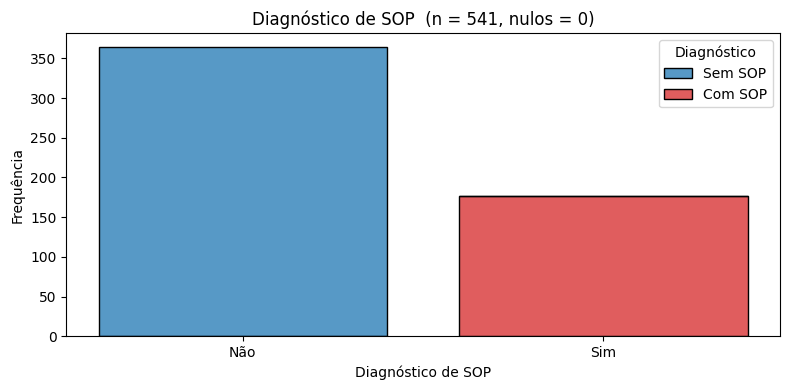

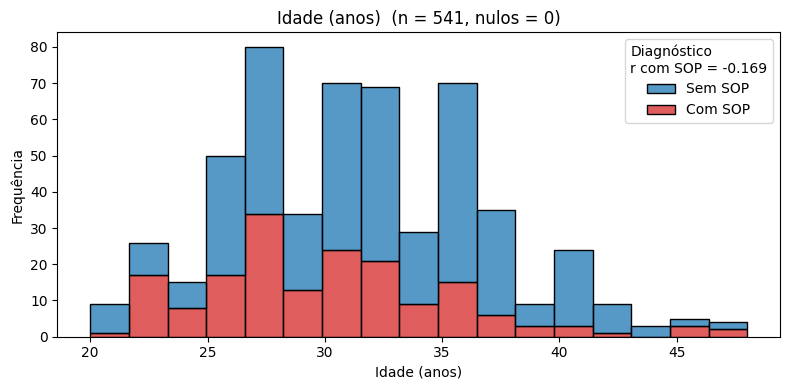

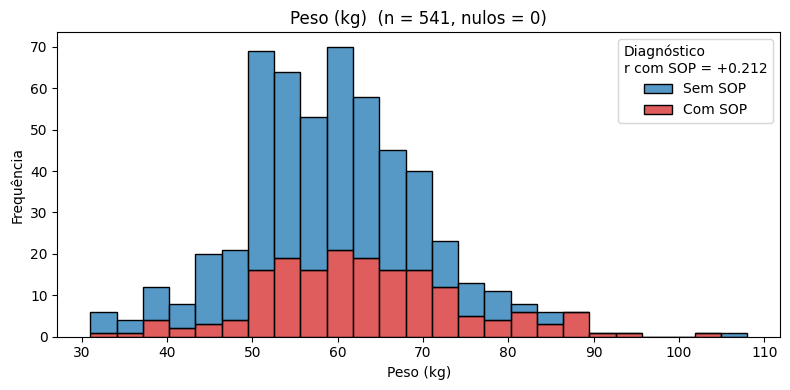

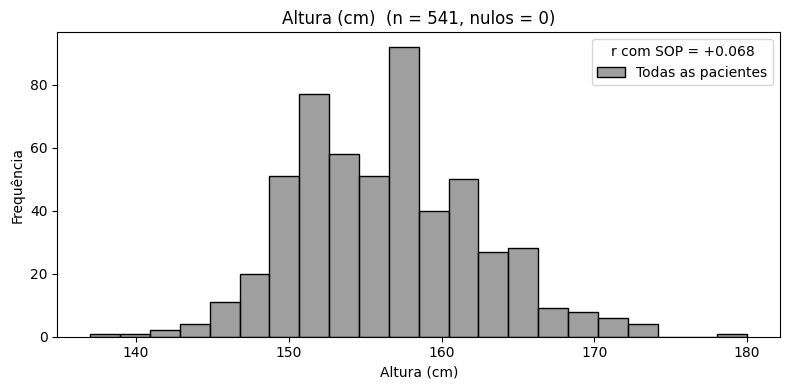

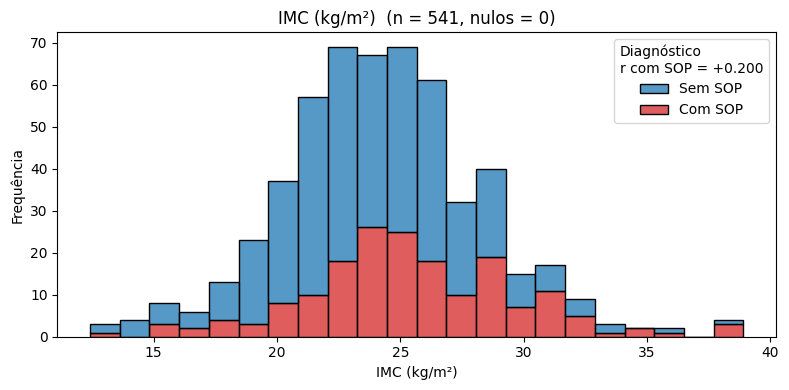

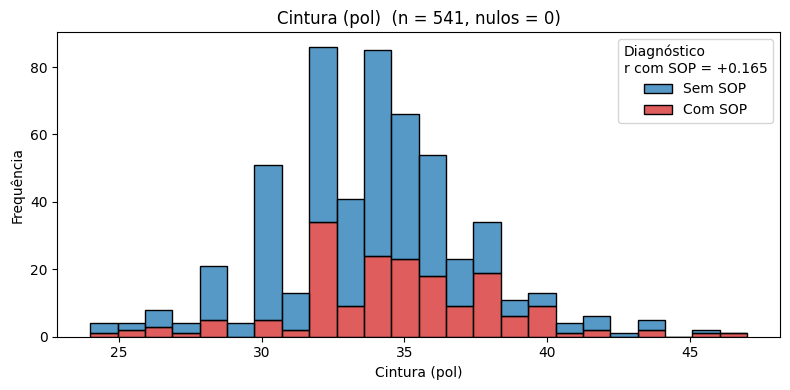

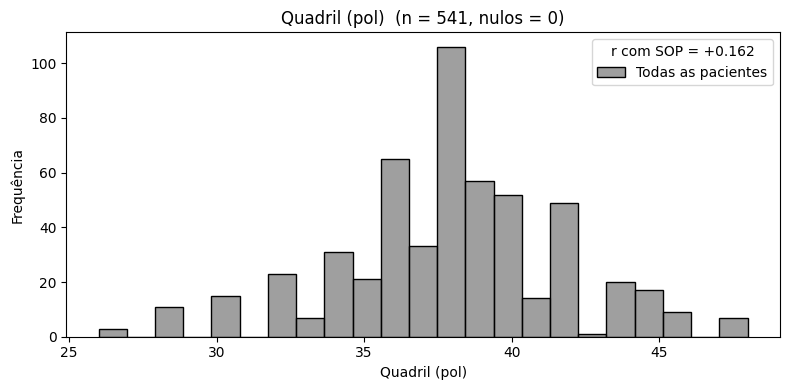

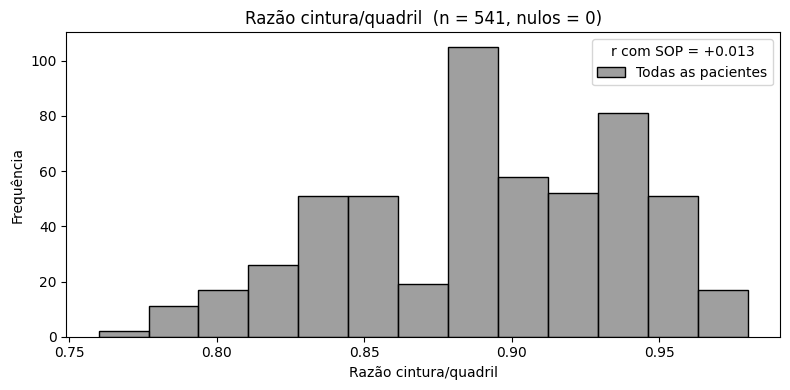

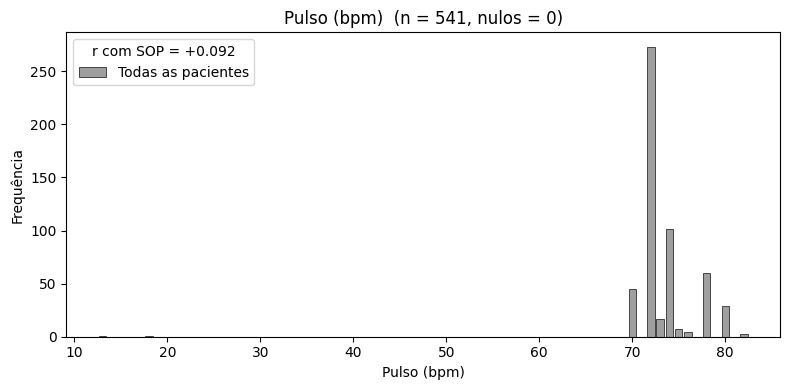

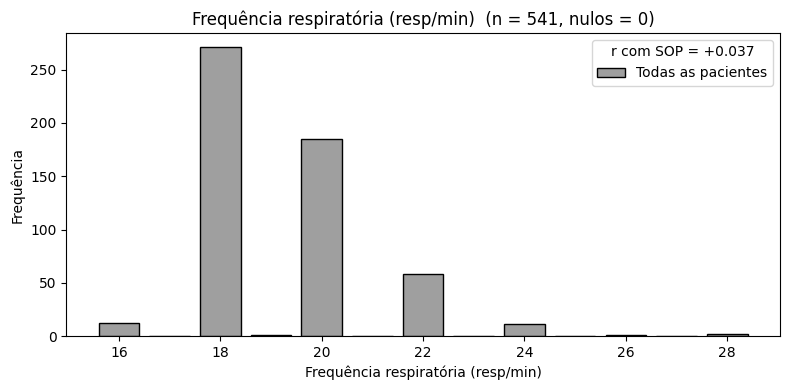

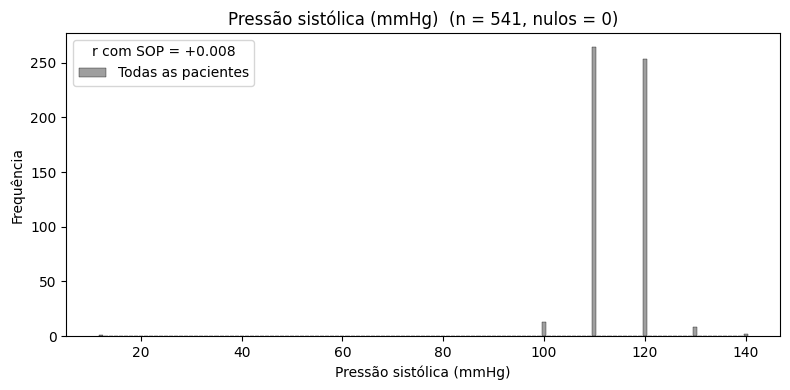

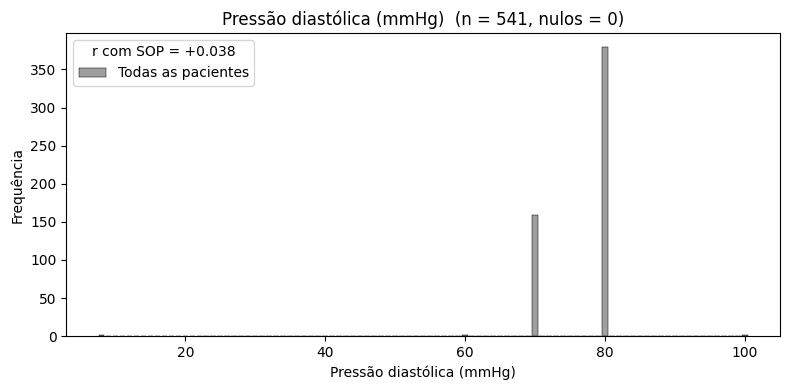

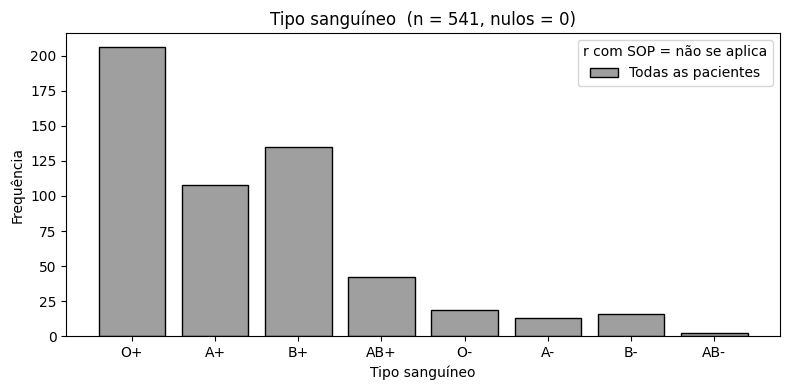

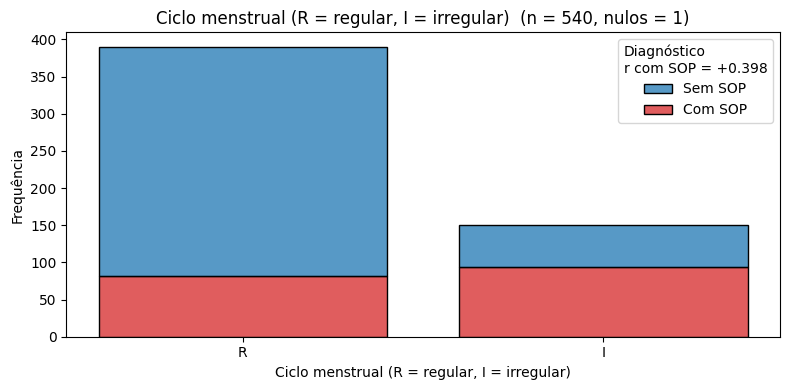

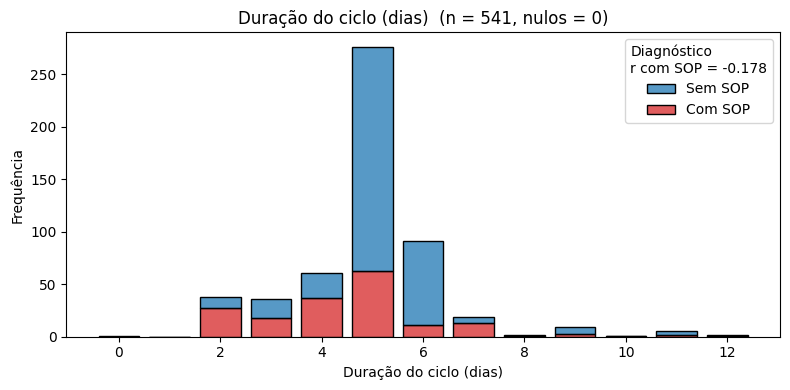

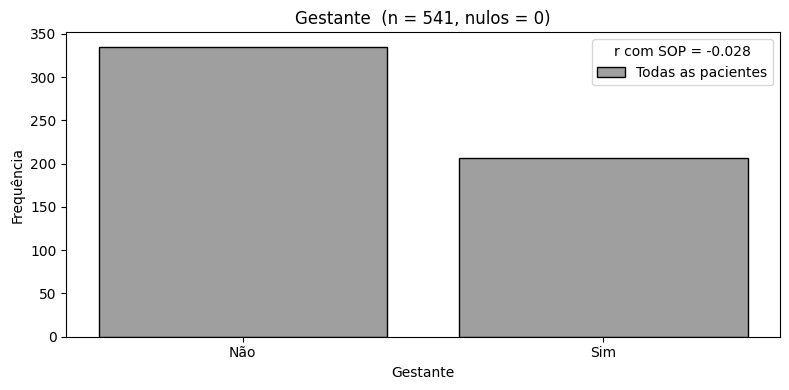

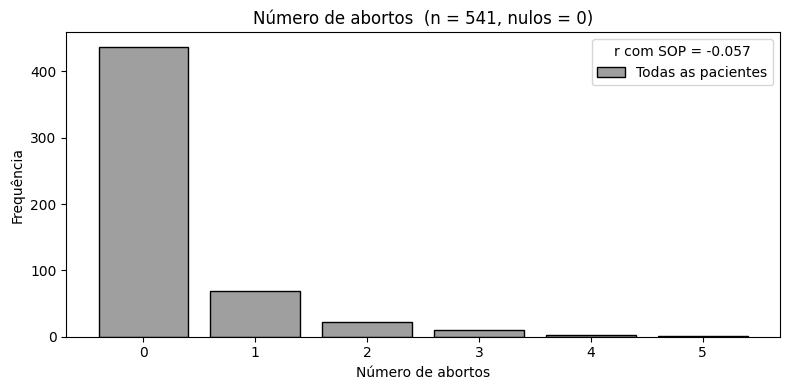

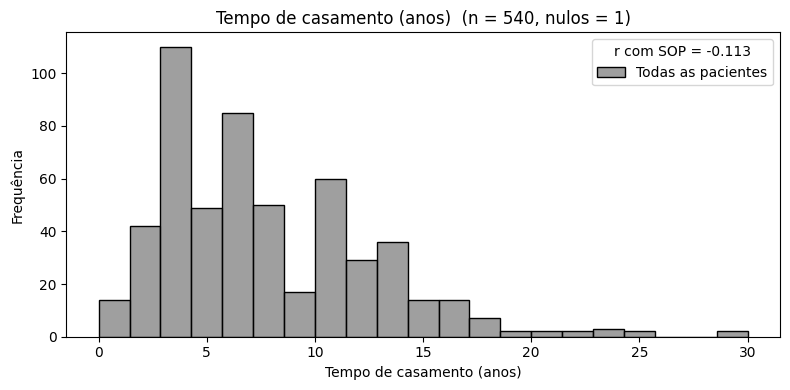

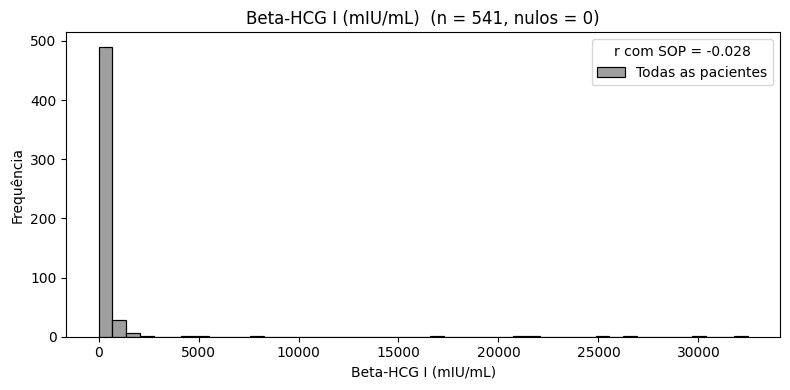

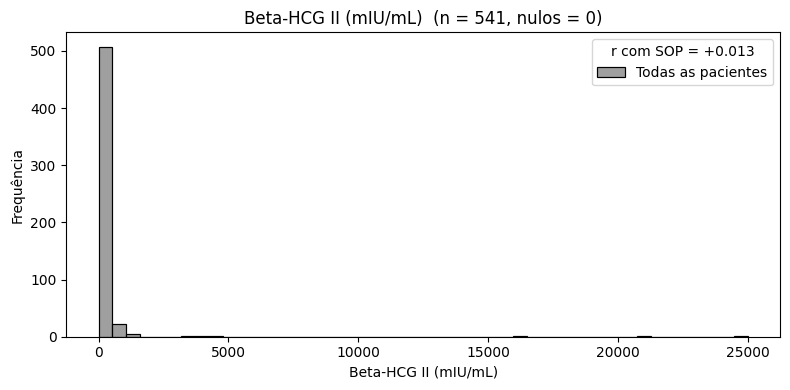

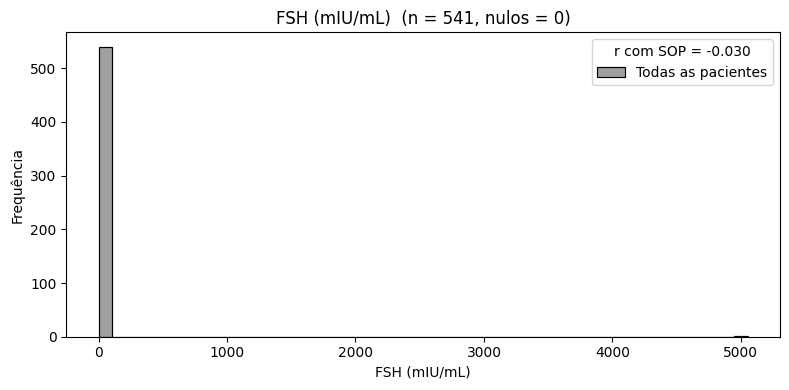

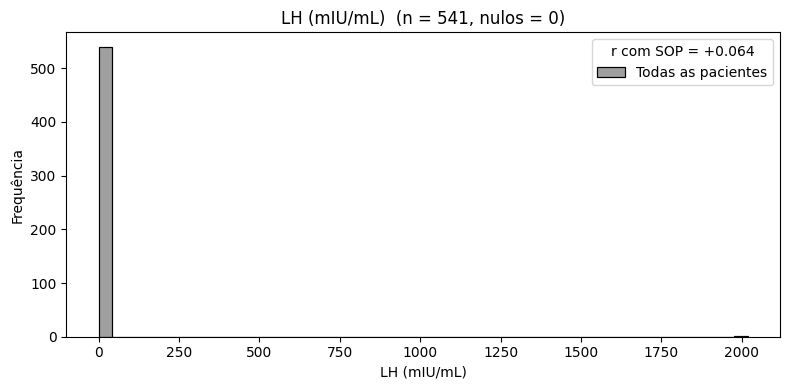

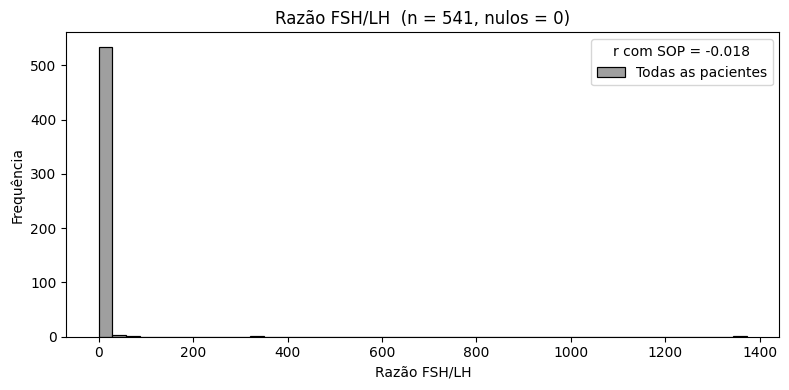

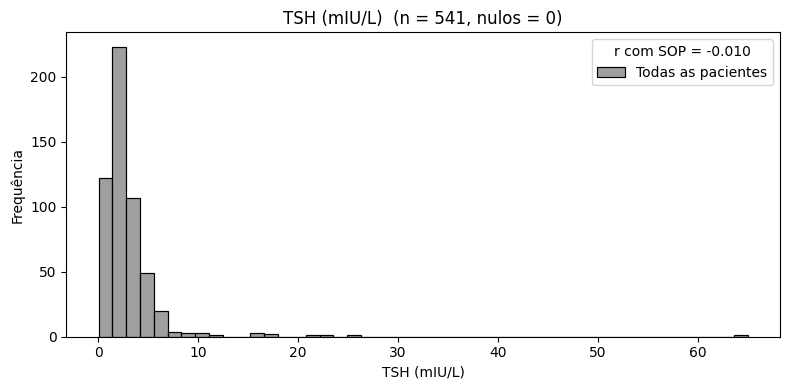

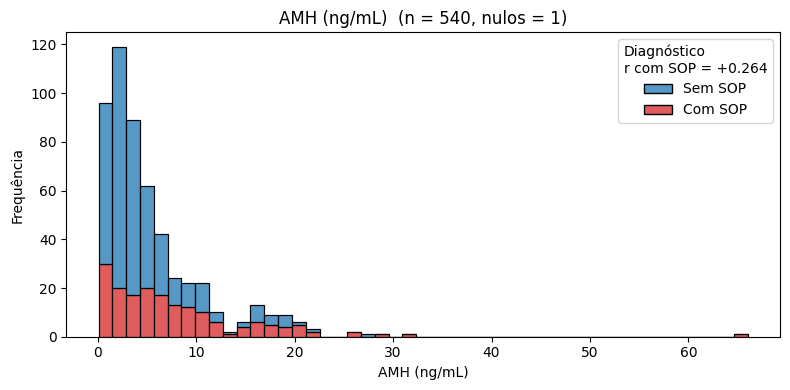

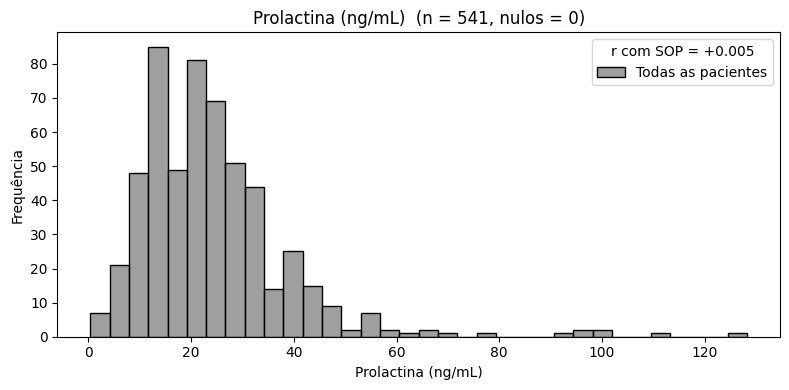

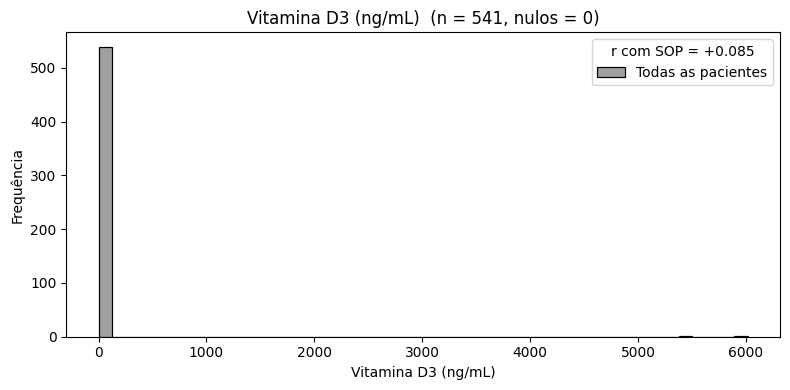

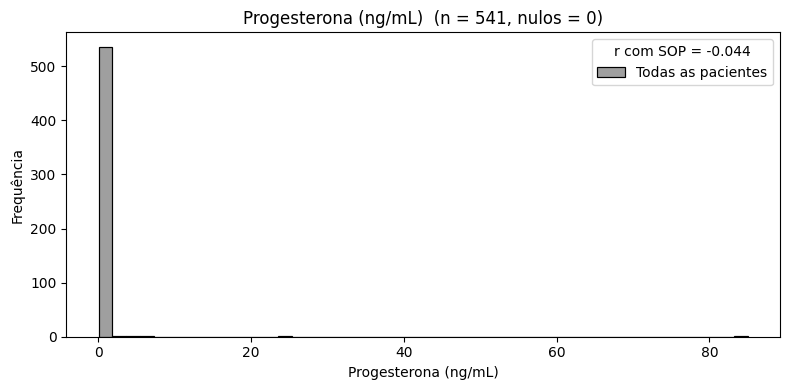

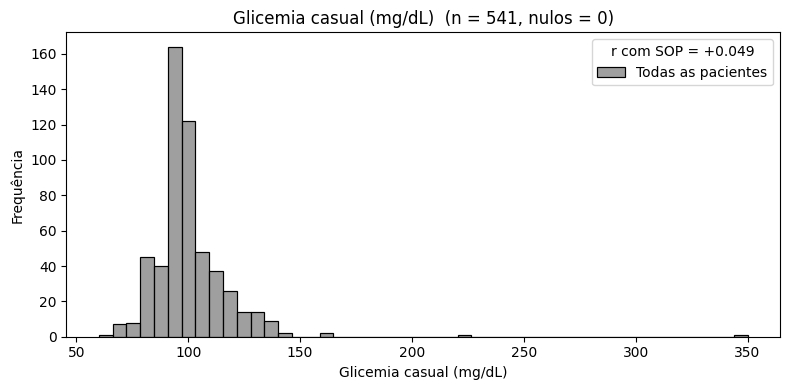

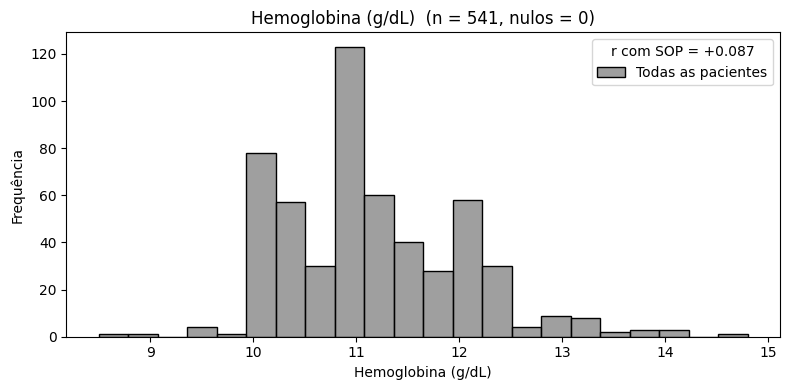

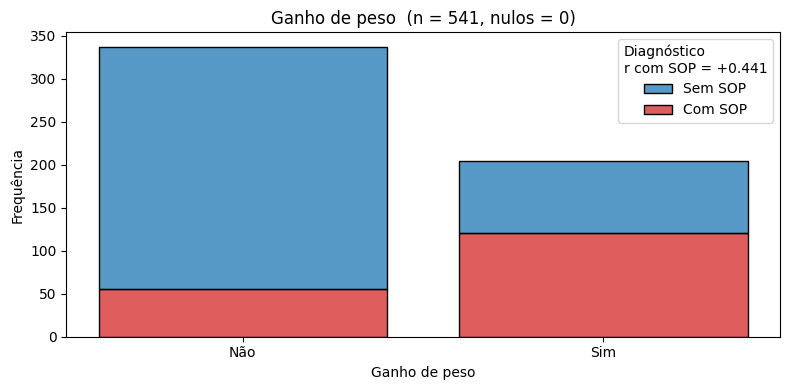

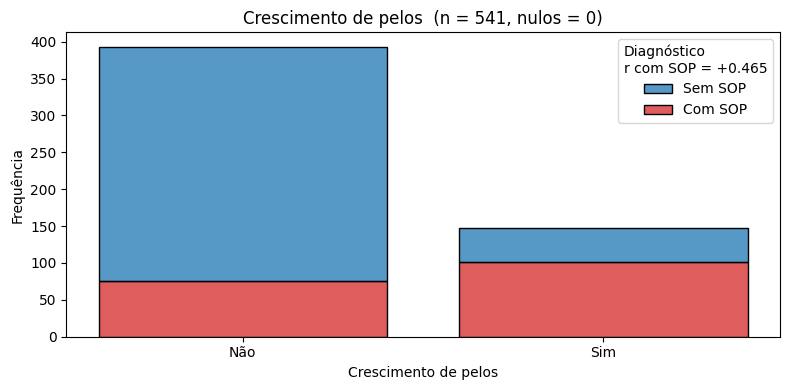

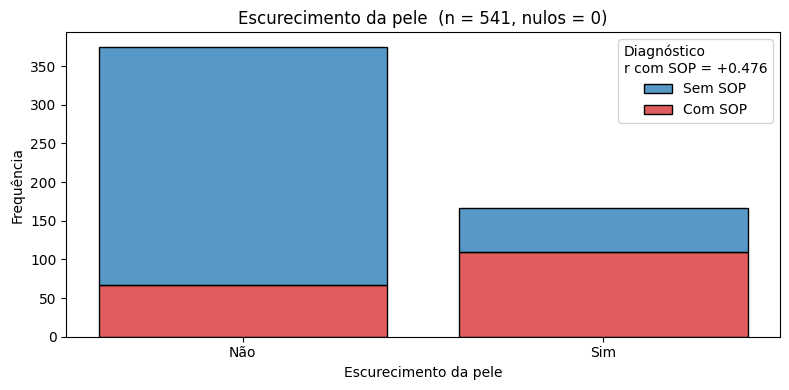

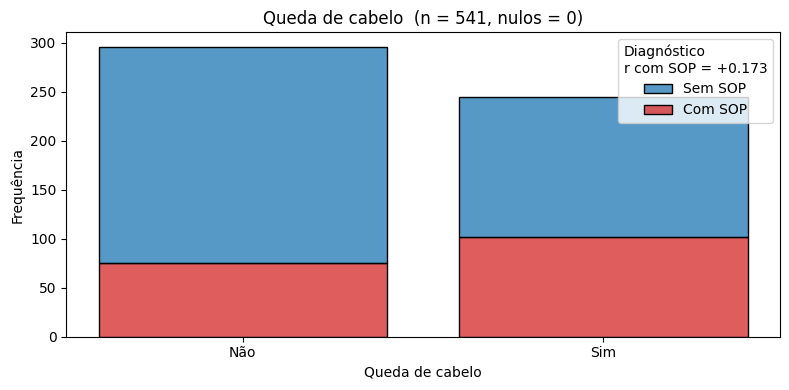

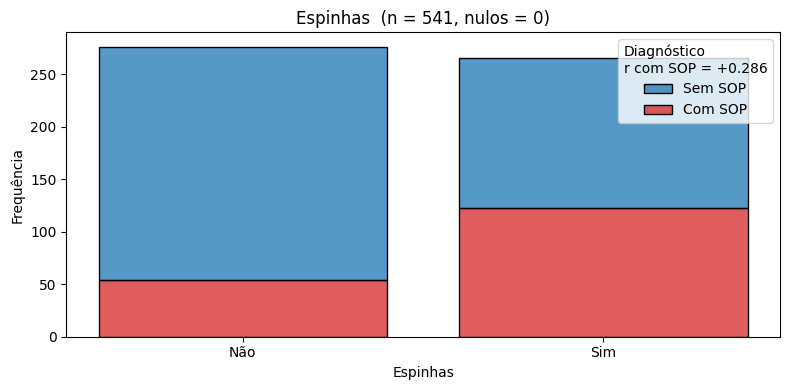

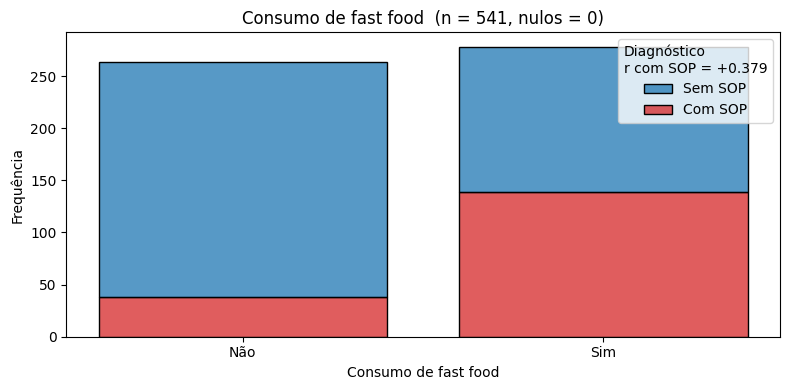

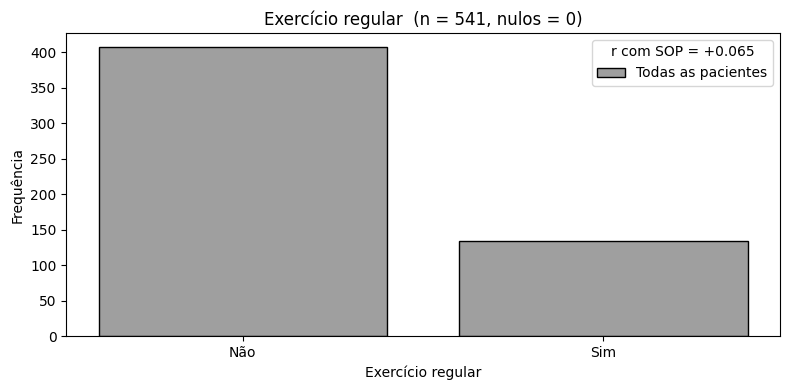

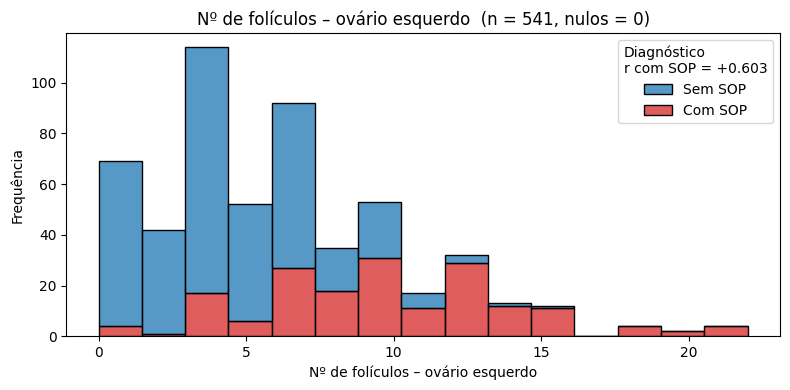

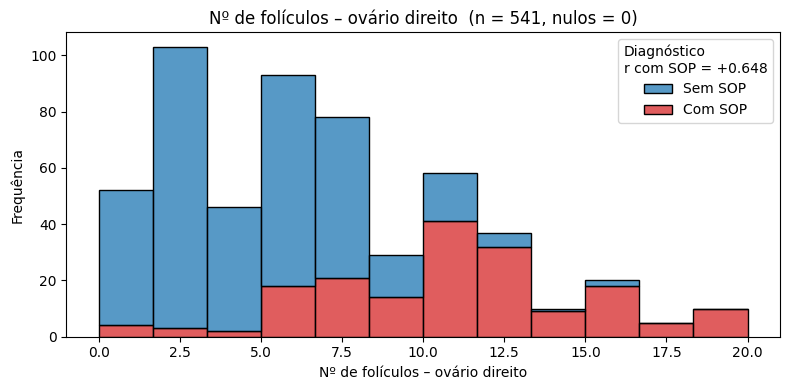

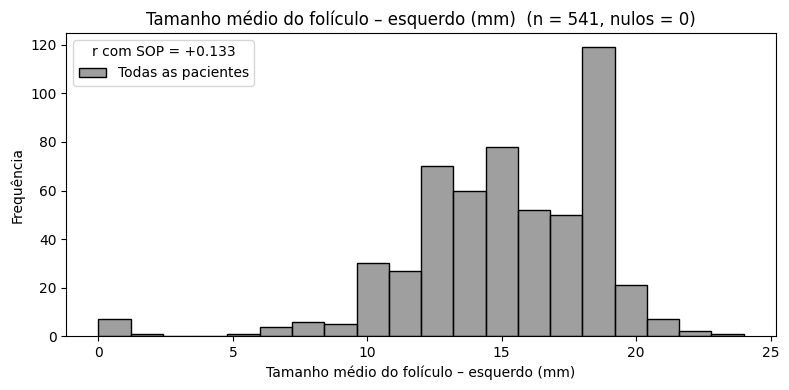

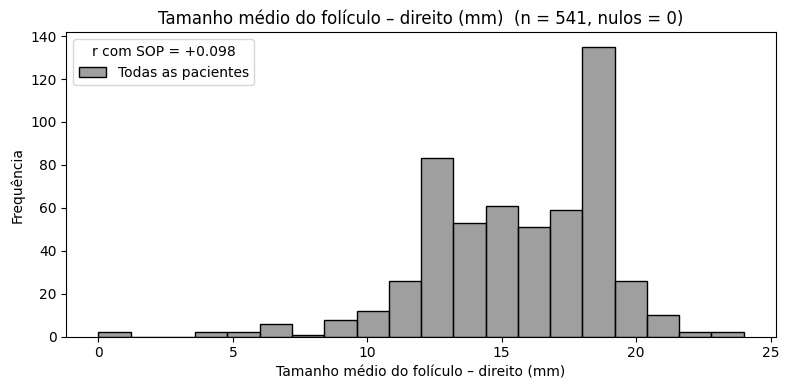

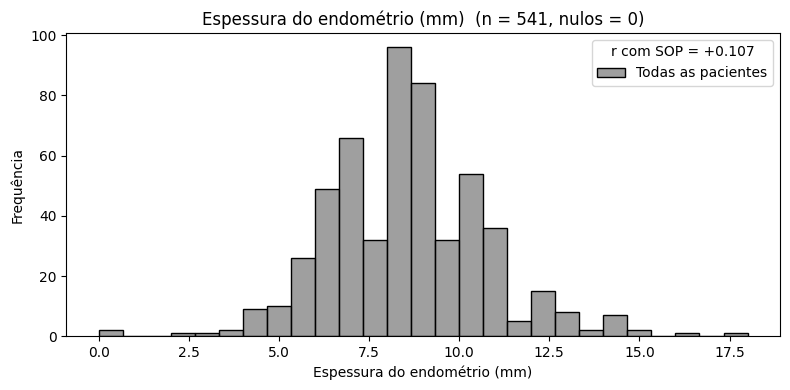

In [28]:
for coluna, rotulo in COLUNAS.items():
    histograma(df, coluna, rotulo, diferenciar=coluna in DIFERENCIAR, r=r_sop.get(coluna),
               arquivo=PASTA_UNIVARIADA / f'{coluna}.png')

## 7. Correlação entre variáveis

Matriz de correlação de Pearson das variáveis numéricas (triângulo inferior). Como várias variáveis são assimétricas (ex.: beta-HCG, AMH), vale comparar com `metodo='spearman'`.

In [29]:
fig = matriz_correlacao(df.drop(columns='id_paciente'), rotulos=COLUNAS,
                        arquivo=PASTA_MULTIVARIADA / 'matriz_correlacao.png')

### 7.1 Vetores de correlação: hábitos × medidas corporais e SOP

Consumo de fast food e prática de exercício contra IMC, razão cintura/quadril, peso e diagnóstico de SOP.

In [30]:
vet_habitos = vetor_correlacao(base, linhas=['fast_food', 'exercicio_regular'],
                 colunas=['imc', 'razao_cintura_quadril', 'peso_kg', 'pcos'],
                 rotulos=COLUNAS, titulo='Hábitos × medidas corporais e SOP (Pearson)',
                 arquivo=PASTA_MULTIVARIADA / 'vetor_habitos_corpo_sop.png')

### 7.2 Vetor de correlação: SOP × todas as variáveis

Correlação de cada variável com o diagnóstico, ordenada pelo módulo. O tipo de ciclo entra codificado como irregular = 1; o tipo sanguíneo (nominal) fica de fora.

In [31]:
vet_sop = vetor_correlacao(base, linhas=['pcos'], rotulos=COLUNAS, ordenar=True,
                 titulo='Correlação com o diagnóstico de SOP (Pearson)',
                 arquivo=PASTA_MULTIVARIADA / 'vetor_sop_todas.png')

## 8. Conclusões

**Variáveis mais associadas à SOP.** As quatro variáveis com maior correlação com o diagnóstico são o número de folículos no ovário direito (r = 0,65) e no esquerdo (r = 0,60), o escurecimento da pele (r = 0,48) e o crescimento excessivo de pelos (r = 0,47). Elas devem ser lidas como marcadores, e não como causas. A contagem elevada de folículos e o crescimento de pelos inclusive fazem parte dos critérios comumente usados para diagnosticar a síndrome. O escurecimento da pele (acantose nigricans) está ligado à resistência à insulina, um dos mecanismos centrais da SOP. Como essas informações provavelmente foram consideradas no próprio diagnóstico registrado no dataset, a correlação delas tende a ser inflada, e elas indicam consequências da síndrome mais do que fatores que a provocam.

**Peso e SOP.** Pacientes com SOP apresentaram peso médio maior (63,0 kg contra 58,0 kg), com correlação positiva fraca (r = 0,21; IMC: r = 0,20). Ainda assim, o peso explica apenas cerca de 4,5% da variação do diagnóstico (r² ≈ 0,045), e a relação não pode ser lida como causal: a própria SOP, por meio da resistência à insulina e das alterações hormonais, pode provocar aumento de peso. Isso é coerente com a correlação mais alta do sintoma "ganho de peso" (r = 0,44). Com essa base de dados não é possível concluir se o peso elevado precede o diagnóstico ou é consequência dele.

**Possível viés de resposta.** Sintomas e hábitos foram registrados por autodeclaração, em perguntas binárias de sim/não, sem medida de frequência ou intensidade, e há indícios de que as pacientes com SOP tendem a responder "sim" com mais frequência. O consumo de fast food, relatado por 78,5% das pacientes com SOP contra 38,2% das demais (r = 0,38), está mais correlacionado com o número de sintomas relatados (r = 0,50) do que com uma medida objetiva como o IMC (r = 0,16). Uma paciente em investigação ou já diagnosticada pode estar mais atenta aos próprios hábitos, ou já ter recebido orientação sobre alimentação. Se esse viés existir, a associação das variáveis de hábito com a SOP (em especial a do fast food) está provavelmente superestimada e não deve ser interpretada como evidência de que esses hábitos causam a síndrome.

In [32]:
# fecha a conexão
conn.close()